In [1]:
import csv
import pandas as pd



# Carga dos datos

In [2]:


ruta = "datos/raw/meteo_alvedro_2021_2025.csv"

contador = 0

with open(ruta, "r", encoding="utf-8", errors="replace") as f:
    leyendo_datos = False

    for linea in f:
        if linea.startswith("Data;"):
            contador += 1
            break
        else:
            contador += 1



In [3]:
df = pd.read_csv(
    ruta,
    encoding="latin-1",
    skiprows= contador -1,
    sep=";",
    decimal=",",
    na_values=["-", ""],
)
df.head()

,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC),Humidade relativa (%),Precipitación (mm),Vento medio (km/h),Presión (hPa)
0,2021-01-01,5.9,3.3,9.1,87,"12,2",11.0,"1.015,7"
1,2021-01-02,5.5,3.1,9.7,91,"9,8",6.4,"1.019,8"
2,2021-01-03,5.6,3.0,8.4,92,"12,4",8.5,"1.018,9"
3,2021-01-04,3.6,-0.3,6.8,92,"4,7",7.8,"1.015,4"
4,2021-01-05,2.8,-1.5,9.4,94,"1,2",6.2,"1.014,6"


# Primeira visual

In [57]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1812 entries, 0 to 1811
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Data                   1812 non-null   str    
 1   Temp. media (ºC)       1803 non-null   float64
 2   Temp. mínima (ºC)      1806 non-null   float64
 3   Temp. máxima (ºC)      1803 non-null   float64
 4   Humidade relativa (%)  1812 non-null   int64  
 5   Precipitación (mm)     1804 non-null   str    
 6   Vento medio (km/h)     1812 non-null   float64
 7   Presión (hPa)          1811 non-null   str    
dtypes: float64(4), int64(1), str(3)
memory usage: 113.4 KB


### 1. Dimensións e tipos de datos
O conxunto de datos contén 1.812 rexistros e 8 columnas: 4 de tipo `float64`, 1 de tipo `int64` e 3 de tipo `str`.

### 2. Valores nulos
As columnas con máis valores ausentes son:
- `Temp. media (ºC)`: 9 nulos.
- `Temp. máxima (ºC)`: 9 nulos.
- `Precipitación (mm)`: 8 nulos.
- `Temp. mínima (ºC)`: 6 nulos.
- `Presión (hPa)`: 1 nulo.

O resto das columnas non presenta valores nulos.

### 3. Conversión de tipos
- `Data`: converter a `datetime`.
- `Precipitación (mm)` e `Presión (hPa)`: converter a `float`, revisando previamente os seus valores.
- Tratar os valores nulos segundo a natureza de cada variable e os obxectivos da análise.

In [58]:
df.describe()

,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC),Humidade relativa (%),Vento medio (km/h)
count,1803.000000,1806.000000,1803.000000,1812.000000,1812.000000
mean,-2.066778,-22.937265,2.546312,80.209161,11.928091
std,408.259393,576.147487,408.453931,8.089905,5.226242
min,-9999.000000,-9999.000000,-9999.000000,36.000000,3.200000
25%,11.350000,7.100000,15.400000,76.000000,8.100000
50%,14.700000,10.900000,18.900000,81.000000,10.350000
75%,18.000000,14.000000,22.800000,86.000000,14.900000
max,31.300000,21.100000,39.200000,100.000000,38.500000


### Detección de valores anómalos (temperaturas)

Detectáronse valores `-9999` nas tres columnas de temperatura, que non corresponden a medicións meteorolóxicas válidas. Identificáronse 3 casos en `Temp. media (ºC)`, 6 en `Temp. mínima (ºC)` e 3 en `Temp. máxima (ºC)`.

Nunha primeira fase, estes valores substituiranse por `NaN` para tratalos como datos ausentes. Posteriormente, imputaranse segundo o criterio que se considere máis axeitado para cada variable.

In [4]:
columnas_numericas = df.select_dtypes(include="number").columns

for columna in columnas_numericas:
    cantidad = (df[columna] == -9999).sum()

    if cantidad > 0:
        print(f"{columna}: {cantidad} valores -9999")

Temp. media (ºC): 3 valores -9999
Temp. mínima (ºC): 6 valores -9999
Temp. máxima (ºC): 3 valores -9999


In [5]:
import numpy as np

columnas_temp = [
    "Temp. media (ºC)",
    "Temp. mínima (ºC)",
    "Temp. máxima (ºC)"
]

df[columnas_temp] = df[columnas_temp].replace(-9999, np.nan)

In [6]:
print("Valores -9999 restantes:")
print((df[columnas_temp] == -9999).sum())

print("\nValores NaN por columna:")
print(df[columnas_temp].isna().sum())

Valores -9999 restantes:
Temp. media (ºC)     0
Temp. mínima (ºC)    0
Temp. máxima (ºC)    0
dtype: int64

Valores NaN por columna:
Temp. media (ºC)     12
Temp. mínima (ºC)    12
Temp. máxima (ºC)    12
dtype: int64


### Comprobación tras a limpeza (temperaturas)

Tras substituír os valores anómalos por `NaN`, as estatísticas descritivas das tres variables de temperatura presentan valores coherentes, sen mínimos nin medias afectados por datos extremos artificiais. Continuaremos coa análise do resto das columnas para identificar posibles anomalías e necesidades de limpeza adicionais.

In [67]:
print(df[columnas_temp].describe())

       Temp. media (ºC)  Temp. mínima (ºC)  Temp. máxima (ºC)
count       1800.000000        1800.000000        1800.000000
mean          14.594778          10.316278          19.215556
std            4.344412           4.773605           4.890894
min            2.100000          -3.200000           6.700000
25%           11.400000           7.100000          15.400000
50%           14.800000          10.900000          18.900000
75%           18.000000          14.000000          22.800000
max           31.300000          21.100000          39.200000


# Conversión de tipos e tratamento de datos faltantes

## Datas

### Análise do formato das datas

Realizouse un reconto dos formatos presentes na columna `Data` para identificar posibles inconsistencias antes da conversión. Detectáronse 1.648 datas no formato `yyyy-mm-dd` e 164 no formato `d/m/yyyy`, sen valores ausentes nin formatos distintos dos contemplados.

Nunha seguinte fase, converteranse todas as datas ao tipo `datetime` para unificar o formato e facilitar a análise temporal.

In [7]:
import pandas as pd

fechas = df["Data"].astype("string").str.strip()

# Clasificar formatos
formatos = {
    "dd/mm/yyyy": r"\d{2}/\d{2}/\d{4}",
    "d/m/yyyy":   r"\d{1,2}/\d{1,2}/\d{4}",
    "yyyy-mm-dd": r"\d{4}-\d{2}-\d{2}",
    "yyyy/mm/dd": r"\d{4}/\d{2}/\d{2}",
}

clasificacion = pd.Series("OTRO FORMATO", index=df.index, dtype="string")
clasificacion[fechas.isna()] = "VALOR AUSENTE"

for nombre, patron in formatos.items():
    coincide = fechas.str.fullmatch(patron, na=False)
    clasificacion[coincide] = nombre

# Conteo por formato
print(clasificacion.value_counts(dropna=False))

# Comprobar que el conteo incluye todas las filas
print("\nTotal de filas del DataFrame:", len(df))
print("Total de filas clasificadas:", clasificacion.count())

# Mostrar valores que no encajan en los formatos contemplados
print("\nFechas con otro formato:")
print(fechas[clasificacion == "OTRO FORMATO"].value_counts(dropna=False))

# Comprobar que la clasificación es exhaustiva
assert clasificacion.count() == len(df)

yyyy-mm-dd    1648
d/m/yyyy       164
Name: count, dtype: Int64

Total de filas del DataFrame: 1812
Total de filas clasificadas: 1812

Fechas con otro formato:
Series([], Name: count, dtype: Int64)


Conversion ao formato datetime de todas as datas.

In [8]:
fechas = df["Data"].astype("string").str.strip()

# Convertir ambos formatos
fecha_iso = pd.to_datetime(
    fechas,
    format="%Y-%m-%d",
    errors="coerce"
)

fecha_europea = pd.to_datetime(
    fechas,
    format="%d/%m/%Y",
    errors="coerce"
)

# Elegir la conversión válida para cada fila
df["Data"] = fecha_iso.fillna(fecha_europea)

# Verificar el resultado
print("Total de filas:", len(df))
print("Fechas no convertidas:", df["Data"].isna().sum())
print(df["Data"].dtype)

Total de filas: 1812
Fechas no convertidas: 0
datetime64[us]


### Detección de días faltantes

Ao comparar as datas rexistradas co calendario diario completo entre o 1 de xaneiro de 2021 e o 31 de decembro de 2025, detectáronse **27 días sen rexistros** dos 1.826 días esperados.

A maioría das ausencias concéntranse en xullo de 2023, cun período continuado do 3 ao 23 de xullo (21 días). Os outros 6 días faltantes están distribuídos entre 2021, 2022, 2023 e 2024.

Será necesario valorar como tratar estas ausencias antes de continuar coa análise temporal.

In [9]:
import pandas as pd

# 1. Convertir la columna Data a datetime
df["Data"] = pd.to_datetime(df["Data"], dayfirst=True, errors="coerce")

# 2. Obtener las fechas mínima y máxima
fecha_min = df["Data"].min()
fecha_max = df["Data"].max()

# 3. Generar un calendario diario completo
todas_las_fechas = pd.date_range(
    start=fecha_min,
    end=fecha_max,
    freq="D"
)

# 4. Obtener las fechas existentes en el DataFrame
fechas_existentes = pd.DatetimeIndex(df["Data"].dropna().unique())

# 5. Identificar los días que faltan
fechas_faltantes = todas_las_fechas.difference(fechas_existentes)

# 6. Mostrar resultados
print("Fecha inicial:", fecha_min)
print("Fecha final:", fecha_max)
print("Total de días esperados:", len(todas_las_fechas))
print("Días con datos:", len(fechas_existentes))
print("Días faltantes:", len(fechas_faltantes))

print("\nFechas que faltan:")
print(fechas_faltantes)

Fecha inicial: 2021-01-01 00:00:00
Fecha final: 2025-12-31 00:00:00
Total de días esperados: 1826
Días con datos: 1799
Días faltantes: 27

Fechas que faltan:
DatetimeIndex(['2021-02-17', '2021-05-25', '2021-11-19', '2022-10-21',
               '2023-04-23', '2023-07-03', '2023-07-04', '2023-07-05',
               '2023-07-06', '2023-07-07', '2023-07-08', '2023-07-09',
               '2023-07-10', '2023-07-11', '2023-07-12', '2023-07-13',
               '2023-07-14', '2023-07-15', '2023-07-16', '2023-07-17',
               '2023-07-18', '2023-07-19', '2023-07-20', '2023-07-21',
               '2023-07-22', '2023-07-23', '2024-03-20'],
              dtype='datetime64[us]', freq=None)


### Tratamento dos datos faltantes

Detectáronse 27 días sen rexistros entre 2021 e 2025: 21 días consecutivos en xullo de 2023 e outros 6 días illados.

- **Xullo de 2023:** excluirase das comparacións mensuais de precipitación e temperatura, xa que a falta de datos pode facer que os resultados non sexan representativos. Non se imputarán valores utilizando a media doutros anos.
- **Días illados:** valorarase a interpolación para as temperaturas e deixarase a precipitación como `NaN` se non se dispón de información fiable para imputala.
- **Visualizacións e análises:** conservaranse os valores `NaN` cando non sexa posible estimar os datos con garantías. As gráficas poden representar os datos dispoñibles, pero será necesario comprobar a cobertura antes de comparar resultados.

## Precipitación e presión

### Conversión de tipos 

Pasamos a float os datos en string da precipitación e da presión. Unha vez feito, xa temos todas as columnas de análise en formato numérico

In [10]:
import pandas as pd
import numpy as np

# Precipitación: sustituir coma decimal y tratar "Ip"
df["Precipitación (mm)"] = (
    df["Precipitación (mm)"]
    .str.strip()
    .replace("Ip", "0")
    .str.replace(",", ".", regex=False)
)

df["Precipitación (mm)"] = pd.to_numeric(
    df["Precipitación (mm)"],
    errors="coerce"
)

# Presión: eliminar separador de miles y sustituir coma decimal
df["Presión (hPa)"] = (
    df["Presión (hPa)"]
    .str.strip()
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
)

df["Presión (hPa)"] = pd.to_numeric(
    df["Presión (hPa)"],
    errors="coerce"
)



### Tratamento de datos faltantes (precipitación)

Observamos 8 datos faltantes na precipitación e 1 dato faltante na presión. Ademais, na precipitación parece haber tamén valores imposibles (como pasaba coa temperatura), de -9999 que distorsionan a media.

In [12]:
print(df.dtypes)

print("\nValores ausentes:")
print(df.isna().sum())

print("\nEstadísticas:")
print(df[[
    "Precipitación (mm)",
    "Presión (hPa)"
]].describe())

Data                     datetime64[us]
Temp. media (ºC)                float64
Temp. mínima (ºC)               float64
Temp. máxima (ºC)               float64
Humidade relativa (%)             int64
Precipitación (mm)              float64
Vento medio (km/h)              float64
Presión (hPa)                   float64
dtype: object

Valores ausentes:
Data                      0
Temp. media (ºC)         12
Temp. mínima (ºC)        12
Temp. máxima (ºC)        12
Humidade relativa (%)     0
Precipitación (mm)        8
Vento medio (km/h)        0
Presión (hPa)             1
dtype: int64

Estadísticas:
       Precipitación (mm)  Presión (hPa)
count         1804.000000    1811.000000
mean            -8.182594    1018.171894
std            332.989514       7.342351
min          -9999.000000     987.900000
25%              0.000000    1014.450000
50%              0.000000    1018.500000
75%              2.900000    1022.500000
max             58.700000    1037.900000


Buscamos a data dos valores imposibles e transformamos ese dato en un NaN. Pasamos a ter 10 Nan na precipitación e 1 na presión. Agora, toca ver cómo se tratan ese valores.

In [14]:
print(
    df.loc[
        df["Precipitación (mm)"] == -9999,
        ["Data", "Precipitación (mm)"]
    ]
)

           Data  Precipitación (mm)
546  2022-07-04             -9999.0
1626 2025-07-12             -9999.0


In [15]:
import numpy as np

df["Precipitación (mm)"] = (
    df["Precipitación (mm)"].replace(-9999, np.nan)
)

In [16]:
print((df["Precipitación (mm)"] == -9999).sum())
print("Valores NaN:", df["Precipitación (mm)"].isna().sum())

0
Valores NaN: 10


#### Imputación a partir do valor medio mensual (precipitación)

Decidimos facer unha imputación dos valores de precipitación a partir do valor medio do mes no que se atopa ese NaN.

In [17]:
medias_mensuales_prec = (
    df.groupby(df["Data"].dt.month)["Precipitación (mm)"]
    .mean()
)

print(medias_mensuales_prec)

Data
1     4.059355
2     3.446099
3     2.772078
4     2.729333
5     2.153205
6     1.733333
7     0.505263
8     0.438961
9     2.486667
10    4.768387
11    5.079333
12    4.418831
Name: Precipitación (mm), dtype: float64


In [18]:
filas_nan = df[df["Precipitación (mm)"].isna()]

resultado = filas_nan[["Data"]].copy()
resultado["Mes"] = resultado["Data"].dt.month
resultado["Media mensual (mm)"] = (
    resultado["Mes"].map(medias_mensuales_prec)
)

print(resultado)

           Data  Mes  Media mensual (mm)
164  2021-06-16    6            1.733333
313  2021-11-12   11            5.079333
546  2022-07-04    7            0.505263
586  2022-08-13    8            0.438961
896  2023-06-21    6            1.733333
1305 2024-08-25    8            0.438961
1313 2024-09-02    9            2.486667
1349 2024-10-08   10            4.768387
1415 2024-12-13   12            4.418831
1626 2025-07-12    7            0.505263


In [19]:
df["Precipitación (mm)"] = df["Precipitación (mm)"].fillna(
    df["Data"].dt.month.map(medias_mensuales_prec)
)
print("Valores NaN:", df["Precipitación (mm)"].isna().sum())
print("Valores negativos:", (df["Precipitación (mm)"] < 0).sum())

Valores NaN: 0
Valores negativos: 0


### Tratamento de datos faltantes (presión)

Aplicamos o mesmo procedemento á presión. O dato faltante pertence ao 3 de setembro do 2024. Imputaremos o valor co dato medio da presión de setembro

In [20]:
print(
    df.loc[
        df["Presión (hPa)"].isna(),
        ["Data", "Presión (hPa)"]
    ]
)

           Data  Presión (hPa)
1314 2024-09-03            NaN


In [21]:
# Calcular la presión media de septiembre
media_septiembre = df.loc[
    df["Data"].dt.month == 9,
    "Presión (hPa)"
].mean()

# Rellenar el valor ausente
df["Presión (hPa)"] = df["Presión (hPa)"].fillna(
    df["Data"].dt.month.map(
        df.groupby(df["Data"].dt.month)["Presión (hPa)"].mean()
    )
)

# Comprobar el resultado para esa fecha
print(
    df.loc[
        df["Data"] == "2024-09-03",
        ["Data", "Presión (hPa)"]
    ]
)

           Data  Presión (hPa)
1314 2024-09-03    1017.156667


Xa temos completadas as columnas de Precipitación e de Presión. Faltan as columnas da temperatura.

## Temperatura

Temos 12 valores faltantes para cada unha das columnas da temperatura. Temos dúas opcións para a imputación:

- Opción A. Inputar mediante interpolación entre a temperatura do día anterior e a do día posterior.
- Opción B. Seguir o procedemento das variables anteriores, ou sexa, imputar pola media mensual.

Dada a cantidade de datas faltantes que temos, é moi posible que o día anterior ou posterior a un NaN de algunha das tres columnas de temperatura coincida cunha data faltante, polo que se creamos unha función encargada de facer esta imputación corremos o risco de que nos de un erro. O máis cómodo é buscar a media mensual, como nas variables anteriores.

In [22]:
columnas_temp = [
    "Temp. media (ºC)",
    "Temp. mínima (ºC)",
    "Temp. máxima (ºC)"
]

filas_temp_nan = df[
    df[columnas_temp].isna().any(axis=1)
]

print(filas_temp_nan[["Data"] + columnas_temp])

           Data  Temp. media (ºC)  Temp. mínima (ºC)  Temp. máxima (ºC)
175  2021-06-27               NaN               10.2               18.4
211  2021-08-02               NaN               12.8               21.2
277  2021-10-07              16.6               11.7                NaN
295  2021-10-25              14.1                NaN               18.5
297  2021-10-27               NaN                7.2               21.8
338  2021-12-08               9.0                4.5                NaN
350  2021-12-20              13.6                NaN               16.5
376  2022-01-15               6.7                NaN               14.0
408  2022-02-16              14.2               11.8                NaN
506  2022-05-25               NaN                8.7               18.4
533  2022-06-21               NaN               11.7               19.1
539  2022-06-27              14.4                NaN               18.8
585  2022-08-12              19.1                NaN            

In [23]:
print("NaN por columna:")
print(df[columnas_temp].isna().sum())

print("\nTotal de filas afectadas:")
print(df[columnas_temp].isna().any(axis=1).sum())

NaN por columna:
Temp. media (ºC)     12
Temp. mínima (ºC)    12
Temp. máxima (ºC)    12
dtype: int64

Total de filas afectadas:
36


In [24]:
columnas_temp = [
    "Temp. media (ºC)",
    "Temp. mínima (ºC)",
    "Temp. máxima (ºC)"
]

for columna in columnas_temp:
    medias_mensuales = df.groupby(df["Data"].dt.month)[columna].transform("mean")
    df[columna] = df[columna].fillna(medias_mensuales)

Xa temos imputados os valores da temperatura. Agora imos visualizar gráficamente as nosas variables para ver se seguimos detectando valores raros, problemas ou outras anormalidades.

# Gráfica de comprobación de valores raros

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

df = df.sort_values("Data").reset_index(drop=True)

# Comprobar que Data tiene formato de fecha
df["Data"] = pd.to_datetime(df["Data"])

## Temperaturas máxima, media e mínima

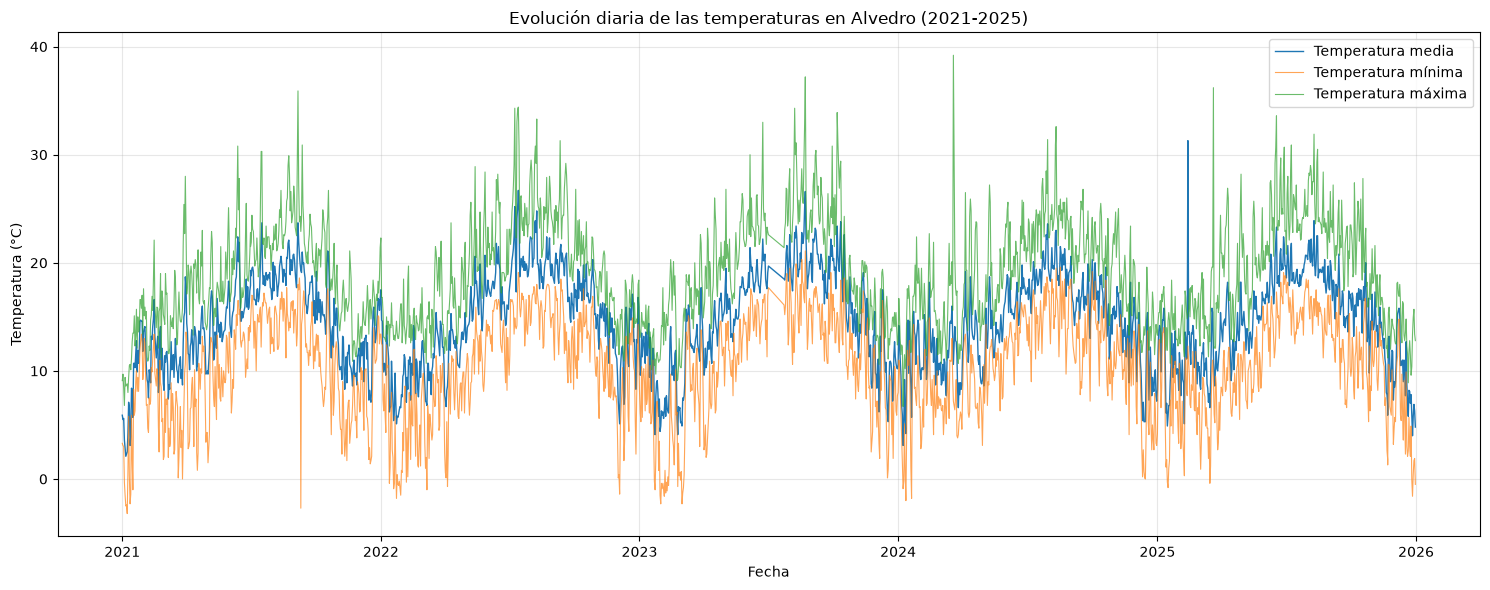

In [28]:
plt.figure(figsize=(15, 6))

plt.plot(
    df["Data"],
    df["Temp. media (ºC)"],
    label="Temperatura media",
    linewidth=1
)

plt.plot(
    df["Data"],
    df["Temp. mínima (ºC)"],
    label="Temperatura mínima",
    linewidth=0.8,
    alpha=0.7
)

plt.plot(
    df["Data"],
    df["Temp. máxima (ºC)"],
    label="Temperatura máxima",
    linewidth=0.8,
    alpha=0.7
)

plt.title("Evolución diaria de las temperaturas en Alvedro (2021-2025)")
plt.xlabel("Fecha")
plt.ylabel("Temperatura (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Detectamos algúns valores incoherentes (medias por enriba de máximas) e valores moi extremos (outliers). Iremos paso a paso. O primeiro é eliminar ese valor medio anormalmente alto de inicios do 2025.

In [29]:
columnas_temp = [
    "Temp. media (ºC)",
    "Temp. mínima (ºC)",
    "Temp. máxima (ºC)"
]

# Detectar temperaturas incoherentes
mascara_incoherentes = (
    (df["Temp. mínima (ºC)"] > df["Temp. media (ºC)"]) |
    (df["Temp. media (ºC)"] > df["Temp. máxima (ºC)"]) |
    (df["Temp. mínima (ºC)"] > df["Temp. máxima (ºC)"])
)

incoherentes = df.loc[
    mascara_incoherentes,
    ["Data"] + columnas_temp
]

print("Número de registros incoherentes:", len(incoherentes))
display(incoherentes)

Número de registros incoherentes: 6


,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC)
783,2023-02-23,5.600000,6.170714,9.1
1089,2024-01-16,9.772727,11.100000,17.9
1195,2024-05-01,8.600000,10.574510,14.3
1485,2025-02-13,31.300000,12.300000,15.2
1744,2025-10-26,16.720915,5.300000,16.6
1745,2025-10-27,9.800000,12.305844,16.7


In [102]:
df.loc[
    df["Data"] == pd.Timestamp("2025-02-13"),
    "Temp. media (ºC)"
] = 13.3

In [103]:
mascara_incoherentes = (
    (df["Temp. mínima (ºC)"] > df["Temp. media (ºC)"]) |
    (df["Temp. media (ºC)"] > df["Temp. máxima (ºC)"])
)

incoherentes = df.loc[
    mascara_incoherentes,
    ["Data", "Temp. media (ºC)",
     "Temp. mínima (ºC)", "Temp. máxima (ºC)"]
]

display(incoherentes)

,Data,Temp. media (ºC),Temp. mínima (ºC),Temp. máxima (ºC)
783,2023-02-23,5.600000,6.170714,9.1
1089,2024-01-16,9.772727,11.100000,17.9
1195,2024-05-01,8.600000,10.574510,14.3
1744,2025-10-26,16.720915,5.300000,16.6
1745,2025-10-27,9.800000,12.305844,16.7


despois desta grafica hai que quitar algún outlier destes que se ven claramente.

In [105]:
import pandas as pd

df = df.sort_values("Data").reset_index(drop=True)

columnas_temp = [
    "Temp. mínima (ºC)",
    "Temp. media (ºC)",
    "Temp. máxima (ºC)"
]

posibles_outliers = []

for columna in columnas_temp:
    serie = df[columna]

    # Mediana local de los 7 días alrededor de cada fecha
    mediana_local = serie.rolling(
        window=7,
        center=True,
        min_periods=5
    ).median()

    diferencia = (serie - mediana_local).abs()

    # Marcar desviaciones grandes para revisarlas
    mascara = diferencia > 10

    resultado = df.loc[mascara, ["Data", columna]].copy()
    resultado["Mediana local"] = mediana_local[mascara]
    resultado["Diferencia"] = diferencia[mascara]
    resultado["Variable"] = columna

    posibles_outliers.append(resultado)

outliers = pd.concat(posibles_outliers, ignore_index=True)

outliers = outliers.sort_values(
    ["Variable", "Diferencia"],
    ascending=[True, False]
)

display(outliers.round(2))

/tmp/ipykernel_5176/55738739.py:42: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(outliers.round(2))


,Data,Temp. mínima (ºC),Mediana local,Diferencia,Variable,Temp. media (ºC),Temp. máxima (ºC)
5,2024-03-19,NaN,18.1,21.1,Temp. máxima (ºC),NaN,39.2
6,2025-03-21,NaN,19.2,17.0,Temp. máxima (ºC),NaN,36.2
2,2021-09-06,NaN,24.3,11.6,Temp. máxima (ºC),NaN,35.9
3,2022-07-11,NaN,33.0,10.7,Temp. máxima (ºC),NaN,22.3
4,2023-08-23,NaN,26.8,10.4,Temp. máxima (ºC),NaN,37.2
0,2021-09-10,-2.7,16.1,18.8,Temp. mínima (ºC),NaN,NaN
1,2024-01-20,-1.8,9.0,10.8,Temp. mínima (ºC),NaN,NaN


In [107]:
fechas_corregir = [
    ("2021-09-06", "Temp. mínima (ºC)"),
    ("2024-03-19", "Temp. máxima (ºC)"),
    ("2025-03-21", "Temp. máxima (ºC)")
]

for fecha, columna in fechas_corregir:
    fecha = pd.Timestamp(fecha)

    vecinos = df.loc[
        df["Data"].isin([
            fecha - pd.Timedelta(days=1),
            fecha + pd.Timedelta(days=1)
        ]),
        ["Data", columna]
    ].sort_values("Data")

    print(f"\nFecha a imputar: {fecha.date()} — {columna}")
    display(vecinos)


Fecha a imputar: 2021-09-06 — Temp. mínima (ºC)


,Data,Temp. mínima (ºC)
247,2021-09-05,13.4
249,2021-09-07,17.5



Fecha a imputar: 2024-03-19 — Temp. máxima (ºC)


,Data,Temp. máxima (ºC)
1152,2024-03-18,15.6



Fecha a imputar: 2025-03-21 — Temp. máxima (ºC)


,Data,Temp. máxima (ºC)
1520,2025-03-20,19.6
1522,2025-03-22,12.1


In [108]:
fecha = pd.Timestamp("2024-03-19")

display(
    df.loc[
        df["Data"].between(
            fecha - pd.Timedelta(days=2),
            fecha + pd.Timedelta(days=2)
        ),
        ["Data", "Temp. máxima (ºC)"]
    ].sort_values("Data")
)

,Data,Temp. máxima (ºC)
1151,2024-03-17,20.1
1152,2024-03-18,15.6
1153,2024-03-19,39.2
1154,2024-03-21,20.7


In [109]:
df.loc[
    df["Data"] == pd.Timestamp("2024-03-19"),
    "Temp. máxima (ºC)"
] = (15.6 + 20.7) / 2

In [110]:
# 1. Temperatura mínima del 6 de septiembre de 2021
fecha = pd.Timestamp("2021-09-06")
columna = "Temp. mínima (ºC)"

anterior = df.loc[df["Data"] == fecha - pd.Timedelta(days=1), columna].iloc[0]
siguiente = df.loc[df["Data"] == fecha + pd.Timedelta(days=1), columna].iloc[0]

df.loc[df["Data"] == fecha, columna] = (anterior + siguiente) / 2


# 2. Temperatura máxima del 21 de marzo de 2025
fecha = pd.Timestamp("2025-03-21")
columna = "Temp. máxima (ºC)"

anterior = df.loc[df["Data"] == fecha - pd.Timedelta(days=1), columna].iloc[0]
siguiente = df.loc[df["Data"] == fecha + pd.Timedelta(days=1), columna].iloc[0]

df.loc[df["Data"] == fecha, columna] = (anterior + siguiente) / 2

In [111]:
fechas_corregidas = pd.to_datetime([
    "2021-09-06",
    "2024-03-19",
    "2025-03-21"
])

display(
    df.loc[
        df["Data"].isin(fechas_corregidas),
        ["Data"] + columnas_temp
    ].sort_values("Data").round(2)
)

/tmp/ipykernel_5176/914425211.py:11: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].sort_values("Data").round(2)


,Data,Temp. mínima (ºC),Temp. media (ºC),Temp. máxima (ºC)
248,2021-09-06,15.45,23.7,35.90
1153,2024-03-19,7.20,10.6,18.15
1521,2025-03-21,9.30,11.5,15.85


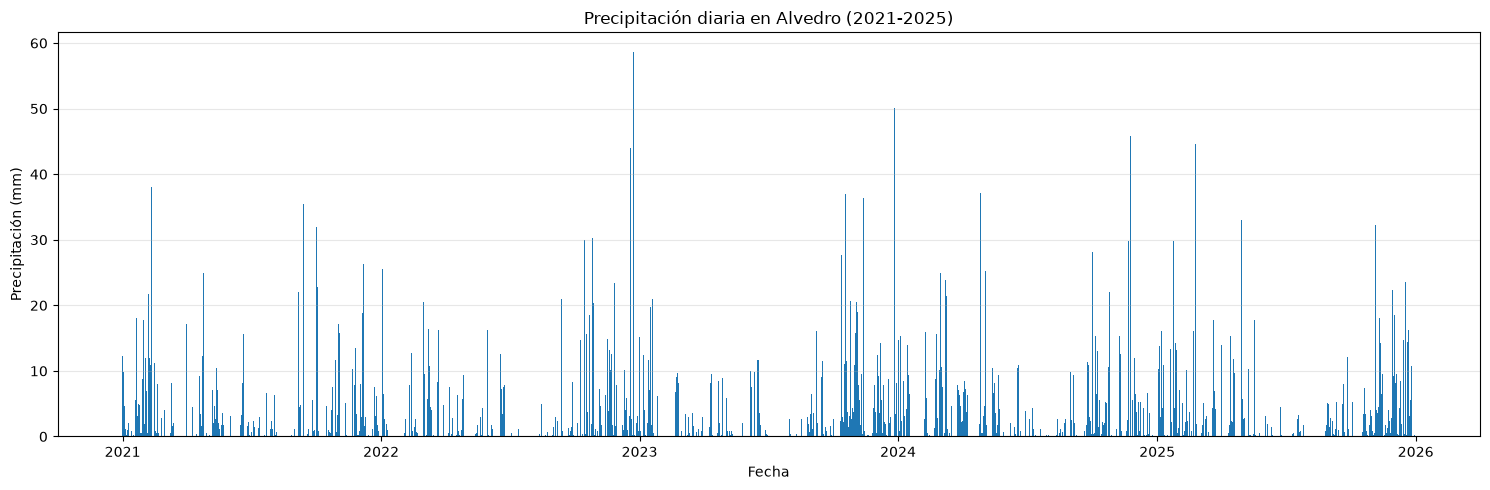

In [95]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.bar(
    df["Data"],
    df["Precipitación (mm)"],
    width=1
)

plt.title("Precipitación diaria en Alvedro (2021-2025)")
plt.xlabel("Fecha")
plt.ylabel("Precipitación (mm)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

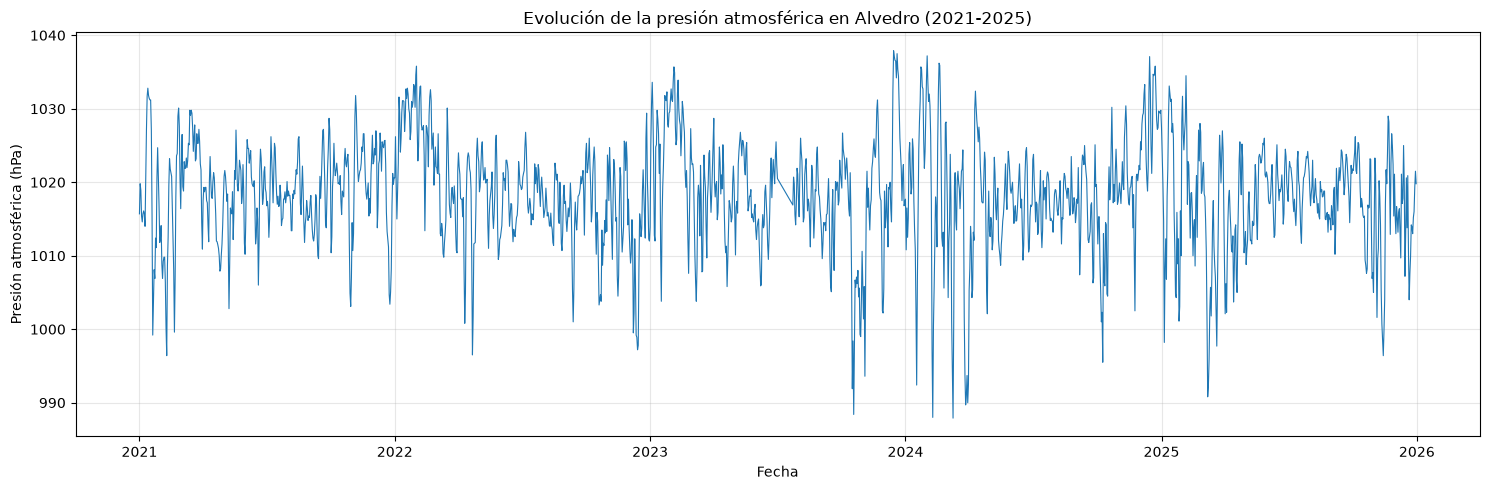

In [96]:
plt.figure(figsize=(15, 5))

plt.plot(
    df["Data"],
    df["Presión (hPa)"],
    linewidth=0.8
)

plt.title("Evolución de la presión atmosférica en Alvedro (2021-2025)")
plt.xlabel("Fecha")
plt.ylabel("Presión atmosférica (hPa)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()